ResNet50 + Attention MIL

Selecciona parches por WSI y usa el mismo MIL, dropout, épocas, tasa de aprendizaje, penalización y balanceo de clases que UNI. Se conservan el índice y sus particiones. La entrada de ResNet50 tiene 2048 dimensiones.


In [1]:
#Librerias

import os
import random
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision.models as models
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Configuracion

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3050


In [3]:
#Rutas

CSV_PATH = Path(r"D:\ProyectoPDAC\mil_index_split.csv")

EMB_DIR = Path(r"D:\ProyectoPDAC\Embeddings_ResNet50_WSI_corregido")
EMB_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR = Path(r"D:\ProyectoPDAC\Resultados_ResNet50_WSI_emparejado_UNI")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_OUT = RESULTS_DIR / "mil_attention_resnet50_best.pt"

print("CSV:", CSV_PATH)
print("Embeddings:", EMB_DIR)
print("Resultados:", RESULTS_DIR)
print("Modelo:", MODEL_OUT)

CSV: D:\ProyectoPDAC\mil_index_split.csv
Embeddings: D:\ProyectoPDAC\Embeddings_ResNet50_WSI_corregido
Resultados: D:\ProyectoPDAC\Resultados_ResNet50_WSI_emparejado_UNI
Modelo: D:\ProyectoPDAC\Resultados_ResNet50_WSI_emparejado_UNI\mil_attention_resnet50_best.pt


In [4]:
#Check de CSV

df = pd.read_csv(CSV_PATH)

print("Total filas:", len(df))
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras filas:")
display(df.head())

# Detectar automáticamente la columna de split
possible_split_cols = ["split", "set", "subset", "partition"]

SPLIT_COL = None
for col in possible_split_cols:
    if col in df.columns:
        SPLIT_COL = col
        break

if SPLIT_COL is None:
    raise ValueError(
        f"No encontré columna de split. Columnas disponibles: {df.columns.tolist()}"
    )

print("\nColumna usada para split:", SPLIT_COL)

print("\nDistribución por split:")
print(df[SPLIT_COL].value_counts())

print("\nDistribución por label:")
print(df["label"].value_counts())

print("\nDistribución label por split:")
print(pd.crosstab(df[SPLIT_COL], df["label"]))
# Validaciones antes de extraer embeddings.
required = {"Slide_ID", "Case_ID", "label", "patch_dir", "num_patches"}
if not required.issubset(df.columns):
    raise ValueError(f"Faltan columnas: {required - set(df.columns)}")
if df[list(required)].isna().any().any():
    raise ValueError("Hay datos obligatorios ausentes en el índice")
if df["Slide_ID"].duplicated().any():
    raise ValueError("Hay Slide_ID duplicados")
if not set(df["label"]).issubset({"tumor", "NAT"}):
    raise ValueError("Etiquetas inesperadas")
if set(df[SPLIT_COL]) != {"train", "val", "test"}:
    raise ValueError("Se requieren los subconjuntos train, val y test")
if (df.groupby("Case_ID")[SPLIT_COL].nunique() > 1).any():
    raise ValueError("Hay pacientes en más de un subconjunto")

def patches_for_slide(row):
    folder = Path(row["patch_dir"])
    if not folder.is_dir():
        raise FileNotFoundError(folder)
    return sorted(folder.glob(f"*_{row['Slide_ID']}_x*_y*.png"))

audit = []
for _, row in df.iterrows():
    files = patches_for_slide(row)
    audit.append({"Slide_ID": row["Slide_ID"],
                  "registrados": int(row["num_patches"]),
                  "seleccionados": len(files)})
audit = pd.DataFrame(audit)
audit.to_csv(RESULTS_DIR / "auditoria_parches_por_WSI.csv", index=False)
bad = audit[(audit["registrados"] != audit["seleccionados"]) |
            (audit["seleccionados"] == 0)]
if not bad.empty:
    display(bad)
    raise ValueError("Los conteos de parches no coinciden; revisar antes de continuar")
print("Auditoría correcta:", len(audit), "WSI. Pacientes separados por subconjunto.")


Total filas: 556

Columnas:
['Slide_ID', 'Case_ID', 'label', 'patch_dir', 'num_patches', 'subset']

Primeras filas:


,Slide_ID,Case_ID,label,patch_dir,num_patches,subset
0,C3L-00017-21,C3L-00017,tumor,D:\ProyectoPDAC\Parches_PDAC_Macenko\tumor\C3L...,1846,train
1,C3L-00017-22,C3L-00017,tumor,D:\ProyectoPDAC\Parches_PDAC_Macenko\tumor\C3L...,1911,train
2,C3L-00017-23,C3L-00017,tumor,D:\ProyectoPDAC\Parches_PDAC_Macenko\tumor\C3L...,1444,train
3,C3L-00017-24,C3L-00017,NAT,D:\ProyectoPDAC\Parches_PDAC_Macenko\NAT\C3L-0...,4445,train
4,C3L-00017-25,C3L-00017,NAT,D:\ProyectoPDAC\Parches_PDAC_Macenko\NAT\C3L-0...,2565,train



Columna usada para split: subset

Distribución por split:
subset
train    392
val       87
test      77
Name: count, dtype: int64

Distribución por label:
label
tumor    381
NAT      175
Name: count, dtype: int64

Distribución label por split:
label   NAT  tumor
subset            
test     27     50
train   122    270
val      26     61
Auditoría correcta: 556 WSI. Pacientes separados por subconjunto.


In [5]:
#Modelo ResNet

model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# quitar clasificador final
model.fc = nn.Identity()

model = model.to(DEVICE)
model.eval()

print("Modelo cargado correctamente")

Modelo cargado correctamente


In [6]:
#Transformaciones

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [7]:
#Carga parches

def load_patch(patch_path):
    
    img = Image.open(patch_path).convert("RGB")
    
    img = transform(img)
    
    return img

In [8]:
# Extracción por WSI; los errores detienen la ejecución.
BATCH_SIZE = 32

for _, row in tqdm(df.iterrows(), total=len(df)):
    slide_id = row["Slide_ID"]
    patch_files = patches_for_slide(row)
    out_path = EMB_DIR / f"{slide_id}.npy"
    # Reanudación solo sobre archivos de la carpeta corregida y conteo válido.
    if out_path.exists():
        cached = np.load(out_path, mmap_mode="r")
        if cached.shape != (len(patch_files), 2048) or not np.isfinite(cached).all():
            raise ValueError(f"Embedding existente inválido: {out_path}")
        del cached
        continue
    embeddings = []
    with torch.no_grad():
        for i in range(0, len(patch_files), BATCH_SIZE):
            batch_imgs = torch.stack([
                load_patch(pf) for pf in patch_files[i:i+BATCH_SIZE]
            ]).to(DEVICE)
            embeddings.append(model(batch_imgs).cpu().numpy())
    embeddings = np.concatenate(embeddings, axis=0)
    if embeddings.shape != (int(row["num_patches"]), 2048):
        raise ValueError(f"Conteo incorrecto: {slide_id}, {embeddings.shape}")
    if not np.isfinite(embeddings).all():
        raise ValueError(f"Valores no finitos: {slide_id}")
    temporary = out_path.with_suffix(".tmp")
    with temporary.open("wb") as handle:
        np.save(handle, embeddings)
    temporary.replace(out_path)
print("Embeddings por WSI completados")


100%|██████████████████████████████████████████████████████████████████████████████| 556/556 [3:44:41<00:00, 24.25s/it]

Embeddings por WSI completados


In [9]:
#Verifica Embeddings

embedding_files = sorted(list(EMB_DIR.glob("*.npy")))

print("Embeddings encontrados:", len(embedding_files))

# revisar algunos
for f in embedding_files[:5]:
    
    arr = np.load(f)
    
    print(f.name, arr.shape)

Embeddings encontrados: 556
C3L-00017-21.npy (1846, 2048)
C3L-00017-22.npy (1911, 2048)
C3L-00017-23.npy (1444, 2048)
C3L-00017-24.npy (4445, 2048)
C3L-00017-25.npy (2565, 2048)


In [10]:
#Busca embedings corruptos

bad_files = []

for f in tqdm(embedding_files):
    
    try:
        arr = np.load(f)
        
        if len(arr.shape) != 2:
            bad_files.append((f.name, "shape"))
            continue
        
        if arr.shape[1] != 2048:
            bad_files.append((f.name, arr.shape))
            continue
        
        if arr.shape[0] == 0:
            bad_files.append((f.name, "empty"))
            continue
        
        if np.isnan(arr).any():
            bad_files.append((f.name, "nan"))
            continue
        
    except Exception as e:
        bad_files.append((f.name, str(e)))

print("Archivos problemáticos:", len(bad_files))

if len(bad_files) > 0:
    print(bad_files[:10])
if bad_files:
    raise ValueError("Se encontraron embeddings problemáticos")
for _, row in df.iterrows():
    path = EMB_DIR / f"{row['Slide_ID']}.npy"
    arr = np.load(path, mmap_mode="r")
    if arr.shape != (int(row["num_patches"]), 2048):
        raise ValueError(f"Dimensiones incorrectas: {path}")
print("Todos los embeddings coinciden con el índice por WSI")


100%|████████████████████████████████████████████████████████████████████████████████| 556/556 [02:08<00:00,  4.33it/s]


Archivos problemáticos: 0
Todos los embeddings coinciden con el índice por WSI


In [11]:
#Muestra embedding con ruta

df["embedding_path"] = df["Slide_ID"].apply(
    lambda x: str(EMB_DIR / f"{x}.npy")
)

display(df.head())

,Slide_ID,Case_ID,label,patch_dir,num_patches,subset,embedding_path
0,C3L-00017-21,C3L-00017,tumor,D:\ProyectoPDAC\Parches_PDAC_Macenko\tumor\C3L...,1846,train,D:\ProyectoPDAC\Embeddings_ResNet50_WSI_correg...
1,C3L-00017-22,C3L-00017,tumor,D:\ProyectoPDAC\Parches_PDAC_Macenko\tumor\C3L...,1911,train,D:\ProyectoPDAC\Embeddings_ResNet50_WSI_correg...
2,C3L-00017-23,C3L-00017,tumor,D:\ProyectoPDAC\Parches_PDAC_Macenko\tumor\C3L...,1444,train,D:\ProyectoPDAC\Embeddings_ResNet50_WSI_correg...
3,C3L-00017-24,C3L-00017,NAT,D:\ProyectoPDAC\Parches_PDAC_Macenko\NAT\C3L-0...,4445,train,D:\ProyectoPDAC\Embeddings_ResNet50_WSI_correg...
4,C3L-00017-25,C3L-00017,NAT,D:\ProyectoPDAC\Parches_PDAC_Macenko\NAT\C3L-0...,2565,train,D:\ProyectoPDAC\Embeddings_ResNet50_WSI_correg...


In [12]:
#Split

train_df = df[df[SPLIT_COL] == "train"].reset_index(drop=True)
val_df   = df[df[SPLIT_COL] == "val"].reset_index(drop=True)
test_df  = df[df[SPLIT_COL] == "test"].reset_index(drop=True)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 392
Val: 87
Test: 77


In [14]:
#Dataset Mil

class MILDataset(Dataset):
    
    def __init__(self, dataframe):
        
        self.df = dataframe.reset_index(drop=True)
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        
        row = self.df.iloc[idx]
        
        emb = np.load(row["embedding_path"])
        
        emb = torch.tensor(emb, dtype=torch.float32)
        
        label = 1 if row["label"] == "tumor" else 0
        
        label = torch.tensor(label, dtype=torch.float32)
        
        return emb, label, row["Slide_ID"]

In [15]:
#Funcion de agrupamiento

def mil_collate(batch):
    
    embeddings = [item[0] for item in batch]
    labels = torch.stack([item[1] for item in batch])
    slide_ids = [item[2] for item in batch]
    
    return embeddings, labels, slide_ids

In [16]:
#Datos

train_dataset = MILDataset(train_df)
val_dataset   = MILDataset(val_df)
test_dataset  = MILDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    collate_fn=mil_collate
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=mil_collate
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=mil_collate
)

print("DataLoaders listos")

DataLoaders listos


In [17]:
class AttentionMIL(nn.Module):

    def __init__(self, input_dim=2048, hidden_dim=256, attn_dim=128, dropout=0.25):
        super().__init__()
        self.feature_proj = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.attention = nn.Sequential(nn.Linear(hidden_dim, attn_dim), nn.Tanh(), nn.Linear(attn_dim, 1))
        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        h = self.feature_proj(x)
        a = self.attention(h)
        a = torch.softmax(a, dim=0)
        m = torch.sum(a * h, dim=0)
        logit = self.classifier(m)
        return (logit.squeeze(0), a.squeeze(1))

In [18]:
# Reiniciar semillas antes de inicializar MIL, como en UNI.
torch.manual_seed(SEED)
np.random.seed(SEED)

mil_model = AttentionMIL(input_dim=2048, hidden_dim=256,
                         attn_dim=128, dropout=0.25).to(DEVICE)
n_neg = int((train_df["label"] == "NAT").sum())
n_pos = int((train_df["label"] == "tumor").sum())
if n_neg == 0 or n_pos == 0:
    raise ValueError("Entrenamiento debe contener ambas clases")
pos_weight_value = n_neg / n_pos
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(mil_model.parameters(), lr=1e-4, weight_decay=1e-5)
print(mil_model)
print("pos_weight:", pos_weight_value)

import json, platform
from importlib.metadata import version, PackageNotFoundError
packages = {}
for package in ["torch", "torchvision", "numpy", "pandas", "Pillow", "scikit-learn"]:
    try:
        packages[package] = version(package)
    except PackageNotFoundError:
        packages[package] = "no disponible"
configuration = {
    "extractor": "torchvision ResNet50", "weights": str(models.ResNet50_Weights.DEFAULT),
    "input_dim": 2048, "hidden_dim": 256, "attn_dim": 128,
    "dropout": 0.25, "epochs": 30, "lr": 1e-4, "weight_decay": 1e-5,
    "optimizer": "Adam", "loss": "BCEWithLogitsLoss",
    "pos_weight": pos_weight_value, "seed": SEED, "threshold": 0.5,
    "checkpoint_selection": "maximum validation AUC; first epoch wins ties",
    "csv_path": str(CSV_PATH), "embedding_dir": str(EMB_DIR),
    "python": platform.python_version(), "packages": packages,
    "cuda": torch.version.cuda, "device": str(DEVICE),
    "resize": [224, 224], "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225]
}
with open(RESULTS_DIR / "configuracion.json", "w", encoding="utf-8") as handle:
    json.dump(configuration, handle, indent=2, ensure_ascii=False)
df.to_csv(RESULTS_DIR / "indice_utilizado.csv", index=False)


AttentionMIL(
  (feature_proj): Sequential(
    (0): Linear(in_features=2048, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
  )
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
  (classifier): Linear(in_features=256, out_features=1, bias=True)
)
pos_weight: 0.45185185185185184


In [19]:
#Funcion epocas

def run_epoch(loader, train=True):
    
    if train:
        mil_model.train()
    else:
        mil_model.eval()
    
    losses = []
    y_true = []
    y_prob = []
    slide_ids_all = []
    
    for embeddings, labels, slide_ids in loader:
        
        # batch_size = 1
        x = embeddings[0].to(DEVICE)
        y = labels[0].to(DEVICE)
        
        if train:
            optimizer.zero_grad()
        
        with torch.set_grad_enabled(train):
            
            logit, attn = mil_model(x)
            loss = criterion(logit.view(1), y.view(1))
            
            if train:
                loss.backward()
                optimizer.step()
        
        prob = torch.sigmoid(logit).detach().cpu().item()
        
        losses.append(loss.item())
        y_true.append(int(y.detach().cpu().item()))
        y_prob.append(prob)
        slide_ids_all.append(slide_ids[0])
    
    return np.mean(losses), np.array(y_true), np.array(y_prob), slide_ids_all

In [20]:
#Entrenamiento

NUM_EPOCHS = 30
best_val_auc = -np.inf

history = []

for epoch in range(1, NUM_EPOCHS + 1):
    
    train_loss, y_train, p_train, _ = run_epoch(train_loader, train=True)
    val_loss, y_val, p_val, _ = run_epoch(val_loader, train=False)
    
    train_pred = (p_train >= 0.5).astype(int)
    val_pred = (p_val >= 0.5).astype(int)
    
    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)
    
    try:
        train_auc = roc_auc_score(y_train, p_train)
    except:
        train_auc = np.nan
    
    try:
        val_auc = roc_auc_score(y_val, p_val)
    except:
        val_auc = np.nan
    
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "train_auc": train_auc,
        "val_auc": val_auc
    })
    
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train AUC: {train_auc:.4f} | Val AUC: {val_auc:.4f} | "
        f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}"
    )
    
    if not np.isnan(val_auc) and val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(mil_model.state_dict(), MODEL_OUT)
        print("  Mejor modelo guardado")
pd.DataFrame(history).to_csv(RESULTS_DIR / "historial_entrenamiento.csv", index=False)


Epoch 01/30 | Train Loss: 0.3463 | Val Loss: 0.2305 | Train AUC: 0.8096 | Val AUC: 0.9628 | Train Acc: 0.7832 | Val Acc: 0.9080
  Mejor modelo guardado
Epoch 02/30 | Train Loss: 0.2404 | Val Loss: 0.1507 | Train AUC: 0.9104 | Val AUC: 0.9842 | Train Acc: 0.8469 | Val Acc: 0.9195
  Mejor modelo guardado
Epoch 03/30 | Train Loss: 0.2000 | Val Loss: 0.1470 | Train AUC: 0.9379 | Val AUC: 0.9830 | Train Acc: 0.8724 | Val Acc: 0.9425
Epoch 04/30 | Train Loss: 0.1837 | Val Loss: 0.1198 | Train AUC: 0.9461 | Val AUC: 0.9830 | Train Acc: 0.8801 | Val Acc: 0.9080
Epoch 05/30 | Train Loss: 0.1711 | Val Loss: 0.1119 | Train AUC: 0.9565 | Val AUC: 0.9861 | Train Acc: 0.8776 | Val Acc: 0.9195
  Mejor modelo guardado
Epoch 06/30 | Train Loss: 0.1374 | Val Loss: 0.1251 | Train AUC: 0.9713 | Val AUC: 0.9836 | Train Acc: 0.9158 | Val Acc: 0.9080
Epoch 07/30 | Train Loss: 0.1166 | Val Loss: 0.1205 | Train AUC: 0.9814 | Val AUC: 0.9792 | Train Acc: 0.9235 | Val Acc: 0.8966
Epoch 08/30 | Train Loss: 0.1107

In [21]:
mil_model.load_state_dict(torch.load(MODEL_OUT, map_location=DEVICE))
mil_model.eval()
print("Mejor modelo cargado desde:", MODEL_OUT)


Mejor modelo cargado desde: D:\ProyectoPDAC\Resultados_ResNet50_WSI_emparejado_UNI\mil_attention_resnet50_best.pt


C:\Users\Usuario\AppData\Local\Temp\ipykernel_4908\3381248089.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mil_model.load_state_dict(torch.load(MODEL_OUT, map_locatio

In [22]:
#Test

test_loss, y_test, p_test, slide_ids_test = run_epoch(
    test_loader,
    train=False
)

pred_test = (p_test >= 0.5).astype(int)

test_acc = accuracy_score(y_test, pred_test)
test_auc = roc_auc_score(y_test, p_test)

test_precision = precision_score(y_test, pred_test)
test_recall = recall_score(y_test, pred_test)
test_f1 = f1_score(y_test, pred_test)

print("\n=========== RESULTADOS TEST ===========")

print(f"Loss        : {test_loss:.4f}")
print(f"Accuracy    : {test_acc:.4f}")
print(f"AUC         : {test_auc:.4f}")
print(f"Precision   : {test_precision:.4f}")
print(f"Recall      : {test_recall:.4f}")
print(f"F1-score    : {test_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, pred_test))
predictions = pd.DataFrame({"Slide_ID": slide_ids_test,
                            "y_true": y_test, "p_tumor": p_test,
                            "y_pred": pred_test})
predictions = predictions.merge(test_df[["Slide_ID", "Case_ID"]],
                                on="Slide_ID", validate="one_to_one")
predictions.to_csv(RESULTS_DIR / "predicciones_test_por_WSI.csv", index=False)
metrics = {"accuracy": float(test_acc), "auc": float(test_auc),
           "precision": float(test_precision), "recall": float(test_recall),
           "f1": float(test_f1), "threshold": 0.5,
           "n_test_wsi": len(test_df),
           "n_test_patients": int(test_df["Case_ID"].nunique())}
import json
with open(RESULTS_DIR / "metricas_test.json", "w", encoding="utf-8") as handle:
    json.dump(metrics, handle, indent=2)



=========== RESULTADOS TEST ===========
Loss        : 0.2752
Accuracy    : 0.8052
AUC         : 0.8896
Precision   : 0.8889
Recall      : 0.8000
F1-score    : 0.8421

Classification Report:

              precision    recall  f1-score   support

           0       0.69      0.81      0.75        27
           1       0.89      0.80      0.84        50

    accuracy                           0.81        77
   macro avg       0.79      0.81      0.79        77
weighted avg       0.82      0.81      0.81        77



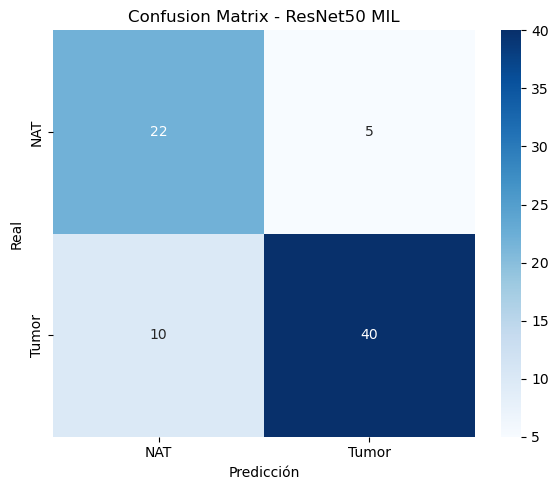

In [23]:
#Matriz de Confusion

cm = confusion_matrix(y_test, pred_test)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NAT", "Tumor"],
    yticklabels=["NAT", "Tumor"]
)

plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Confusion Matrix - ResNet50 MIL")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "matriz_confusion_test.png", dpi=300, bbox_inches="tight")
plt.show()

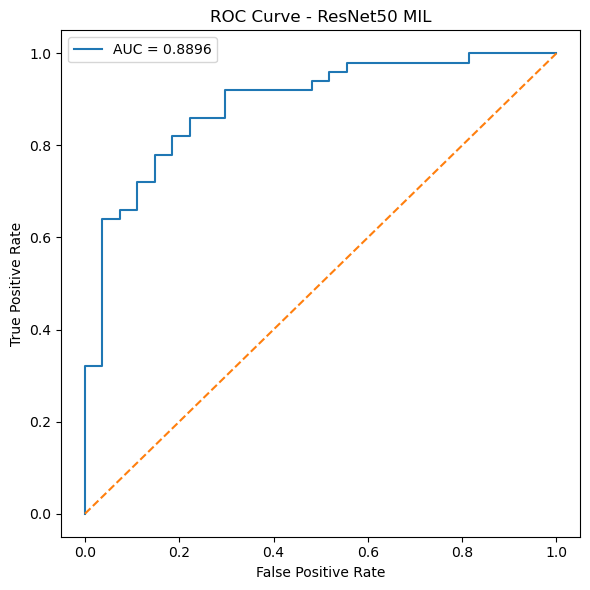

In [24]:
#ROC

fpr, tpr, _ = roc_curve(y_test, p_test)

plt.figure(figsize=(6,6))

plt.plot(fpr, tpr, label=f"AUC = {test_auc:.4f}")

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - ResNet50 MIL")

plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "roc_test.png", dpi=300, bbox_inches="tight")
plt.show()